# Titanic survival — exploratory analysis

## Summary
- Development population: **712 passengers**; final validation: **179 passengers**. Validation outcomes are excluded from EDA.
- Missingness: **Age 19.2%**, **Cabin 77.5%**, **Embarked 0.3%**.
- Survival differs across sex/class combinations and shows a nonmonotonic association with family size.
- Fares are right-skewed; raw and log-transformed distributions are inspected without altering the source data.
- **67/179 validation passengers** share a normalized ticket with development passengers. Generalization to new travel groups requires separate assessment.

These observations guided the experiments in [RESULTS.md](RESULTS.md).

## Scope and method
Source: Kaggle Titanic competition, **`train.csv` only**. Fixed 80/20 split, seed 42, stratified by survival.
EDA uses the development subset. Validation features are retained solely to audit group overlap.
Group survival summaries include sample sizes and descriptive 95% Wilson intervals.
Intervals assume independent binomial outcomes; shared travel groups limit that approximation.

## 1. Setup

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display
from data import load_data, split_data

ROOT = Path.cwd()
OUTPUT = ROOT / "artifacts" / "eda"
OUTPUT.mkdir(parents=True, exist_ok=True)
COLORS = {0: "#B57516", 1: "#24628C"}
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 14)
pd.set_option("display.max_rows", 25)

## 2. Population and split

In [2]:
development, validation = split_data(load_data())
holdout_features = validation.drop(columns="Survived").copy()
split_sizes = {"Development": len(development), "Reserved validation": len(validation)}
del validation
assert set(development.PassengerId).isdisjoint(holdout_features.PassengerId)
display(pd.Series(split_sizes, name="Passengers").to_frame())
display(development.head())

,Passengers
Development,712
Reserved validation,179


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
692,693,1,3,"Lam, Mr. Ali",male,NaN,0,0,1601,56.4958,NaN,S
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,NaN,0,0,239854,0.0000,NaN,S
527,528,0,1,"Farthing, Mr. John",male,NaN,0,0,PC 17483,221.7792,C95,S
855,856,1,3,"Aks, Mrs. Sam (Leah Rosen)",female,18.0,0,1,392091,9.3500,NaN,S
801,802,1,2,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",female,31.0,1,1,C.A. 31921,26.2500,NaN,S


## 3. Data dictionary

| Field | Meaning | Role |
| --- | --- | --- |
| PassengerId | Passenger identifier | Split/audit key |
| Survived | 0 = did not survive; 1 = survived | Target |
| Pclass | Ticket class 1, 2, 3 | Ordered category |
| Name | Passenger name and title | Text; candidate title information |
| Sex | Recorded sex | Category |
| Age | Age in years | Incomplete numeric field |
| SibSp | Siblings/spouses aboard | Count |
| Parch | Parents/children aboard | Count |
| Ticket | Ticket identifier | Travel-group proxy |
| Fare | Recorded fare | Numeric; payment unit requires care |
| Cabin | Cabin string | Sparse text; candidate deck information |
| Embarked | C = Cherbourg; Q = Queenstown; S = Southampton | Incomplete category |

## 4. Data quality and missingness

In [3]:
audit = pd.DataFrame({
    "dtype": development.dtypes.astype(str),
    "missing_n": development.isna().sum(),
    "missing_pct": development.isna().mean().mul(100).round(1),
    "distinct_nonmissing": development.nunique(),
}).sort_values("missing_pct", ascending=False)
display(audit)
quality = pd.Series({
    "Duplicate passenger IDs": development.PassengerId.duplicated().sum(),
    "Exact duplicate rows excluding ID": development.drop(columns="PassengerId").duplicated().sum(),
    "Negative age": development.Age.lt(0).sum(),
    "Negative fare": development.Fare.lt(0).sum(),
    "Invalid class": (~development.Pclass.isin([1, 2, 3])).sum(),
    "Invalid sex": (~development.Sex.isin(["male", "female"])).sum(),
    "Invalid port (excluding missing)": (~development.Embarked.dropna().isin(["C", "Q", "S"])).sum(),
    "Negative family counts": development[["SibSp", "Parch"]].lt(0).any(axis=1).sum(),
    "Fractional family counts": development[["SibSp", "Parch"]].mod(1).ne(0).any(axis=1).sum(),
    "Zero fares": development.Fare.eq(0).sum(),
})
display(quality.to_frame("Rows"))
audit.to_csv(OUTPUT / "column_audit.csv")

,dtype,missing_n,missing_pct,distinct_nonmissing
Cabin,str,552,77.5,127
Age,float64,137,19.2,85
Embarked,str,2,0.3,3
PassengerId,int64,0,0.0,712
Survived,int64,0,0.0,2
Pclass,int64,0,0.0,3
Name,str,0,0.0,712
Sex,str,0,0.0,2
SibSp,int64,0,0.0,7
Parch,int64,0,0.0,7


,Rows
Duplicate passenger IDs,0
Exact duplicate rows excluding ID,0
Negative age,0
Negative fare,0
Invalid class,0
Invalid sex,0
Invalid port (excluding missing),0
Negative family counts,0
Fractional family counts,0
Zero fares,14


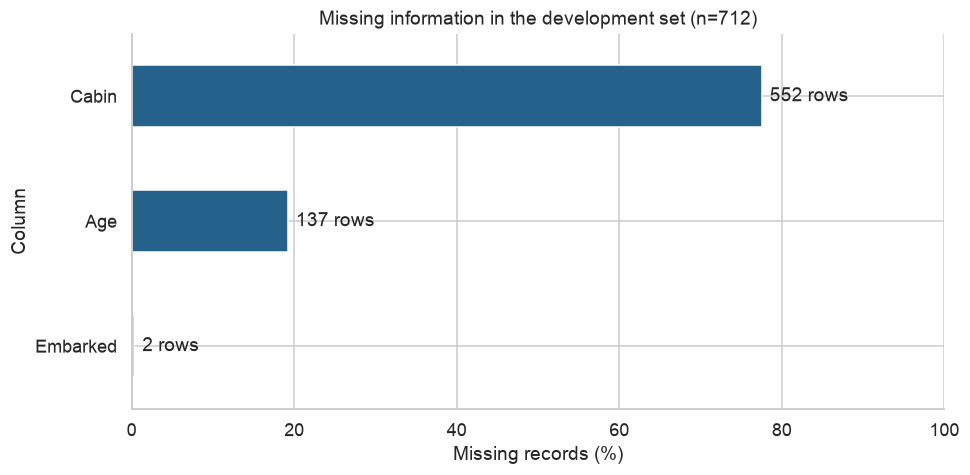

In [4]:
missing = audit.loc[audit.missing_n.gt(0)].sort_values("missing_pct")
if not missing.empty:
    ax = missing.missing_pct.plot.barh(color="#24628C")
    ax.set(xlim=(0, 100), xlabel="Missing records (%)", ylabel="Column",
           title=f"Missing information in the development set (n={len(development)})")
    for y, row in enumerate(missing.itertuples()):
        ax.text(row.missing_pct + 1, y, f"{row.missing_n} rows", va="center")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values in the development set.")

No duplicate passenger IDs or violations of the listed domain checks were found in development data.
Age is absent in 137 rows; cabin in 552; port in two. There are 14 zero fares.

## 5. Group summaries

In [5]:
def survival_summary(frame, by):
    table = frame.groupby(by, dropna=False, observed=True).Survived.agg(
        passengers="size", survivors="sum", rate="mean"
    )
    n, p, z = table.passengers, table.rate, 1.96
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    radius = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator
    return table.assign(lower95=(center - radius).clip(0, 1),
                        upper95=(center + radius).clip(0, 1))


def plot_survival(frame, by, title):
    table = survival_summary(frame, by)
    labels = [
        f"{'Unknown' if pd.isna(key) else key} (n={int(n)})"
        for key, n in zip(table.index, table.passengers)
    ]
    fig, ax = plt.subplots(figsize=(9, max(3.5, len(table) * 0.45)))
    ax.errorbar(table.rate, np.arange(len(table)),
                xerr=[table.rate - table.lower95, table.upper95 - table.rate],
                fmt="o", capsize=4, color="#24628C")
    ax.set(yticks=np.arange(len(table)), yticklabels=labels, xlim=(0, 1),
           xlabel="Survival rate (95% Wilson interval)", ylabel=str(by), title=title)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()
    return table


def show_table(table):
    display(table.style.format({"rate": "{:.1%}", "lower95": "{:.1%}", "upper95": "{:.1%}"}))

## 6. Outcome balance

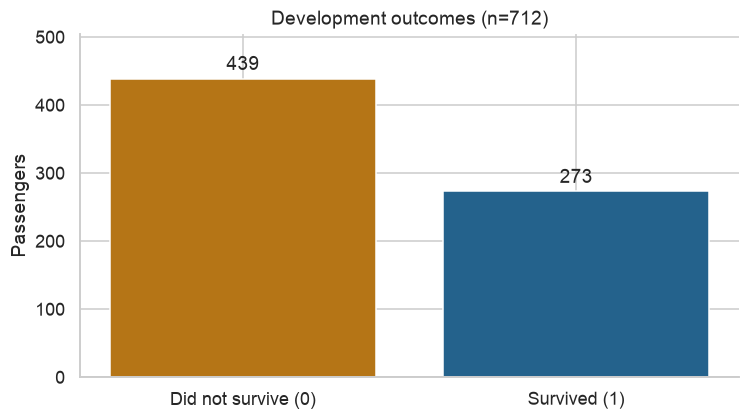

In [6]:
target_counts = development.Survived.value_counts().sort_index()
majority_accuracy = target_counts.max() / target_counts.sum()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["Did not survive (0)", "Survived (1)"], target_counts, color=[COLORS[0], COLORS[1]])
ax.bar_label(ax.containers[0], padding=3)
ax.set(ylabel="Passengers", title=f"Development outcomes (n={len(development)})")
ax.set_ylim(0, target_counts.max() * 1.15)
plt.tight_layout()
plt.show()

In [7]:
display(pd.Series({
    "Development survival rate": development.Survived.mean(),
    "Majority-class development accuracy": majority_accuracy,
}).map(lambda value: f"{value:.1%}").to_frame("Value"))

,Value
Development survival rate,38.3%
Majority-class development accuracy,61.7%


The majority-class reference is **61.7% development accuracy**. It is not a validation result.

## 7. Sex, passenger class, and embarkation

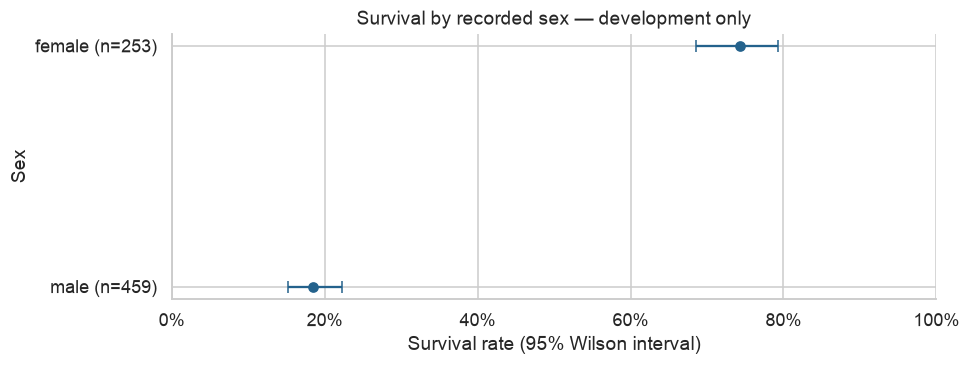

,passengers,survivors,rate,lower95,upper95
Sex,,,,,
female,253,188,74.3%,68.6%,79.3%
male,459,85,18.5%,15.2%,22.3%


In [8]:
sex_rates = plot_survival(development, "Sex", "Survival by recorded sex — development only")
show_table(sex_rates)

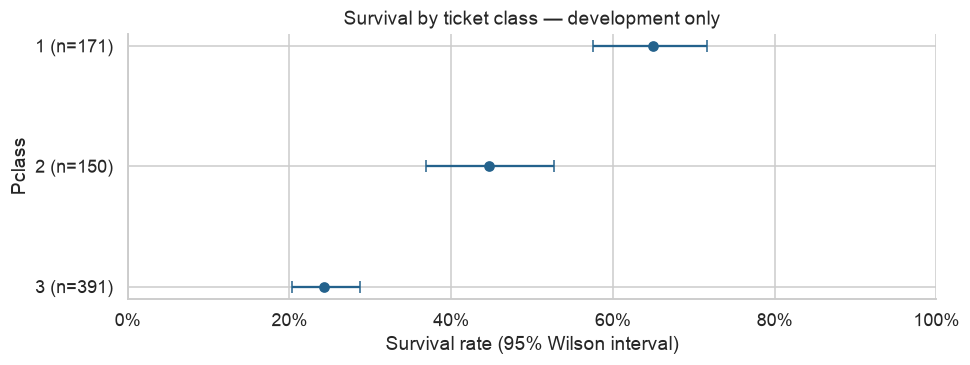

,passengers,survivors,rate,lower95,upper95
Pclass,,,,,
1,171,111,64.9%,57.5%,71.7%
2,150,67,44.7%,36.9%,52.7%
3,391,95,24.3%,20.3%,28.8%


In [9]:
class_rates = plot_survival(development, "Pclass", "Survival by ticket class — development only")
show_table(class_rates)

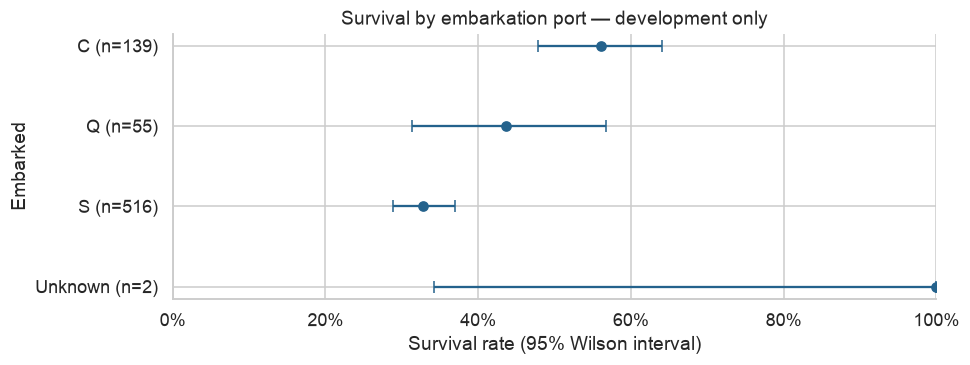

,passengers,survivors,rate,lower95,upper95
Embarked,,,,,
C,139,78,56.1%,47.8%,64.1%
Q,55,24,43.6%,31.4%,56.7%
S,516,169,32.8%,28.8%,36.9%
nan,2,2,100.0%,34.2%,100.0%


In [10]:
port_rates = plot_survival(development, "Embarked", "Survival by embarkation port — development only")
show_table(port_rates)

Female survival is **74.3% (188/253)**; male survival is **18.5% (85/459)**.
Class-specific survival is **64.9%**, **44.7%**, and **24.3%** for classes 1–3.
Port rates require joint analysis because passenger composition differs.

## 8. Joint patterns and passenger composition

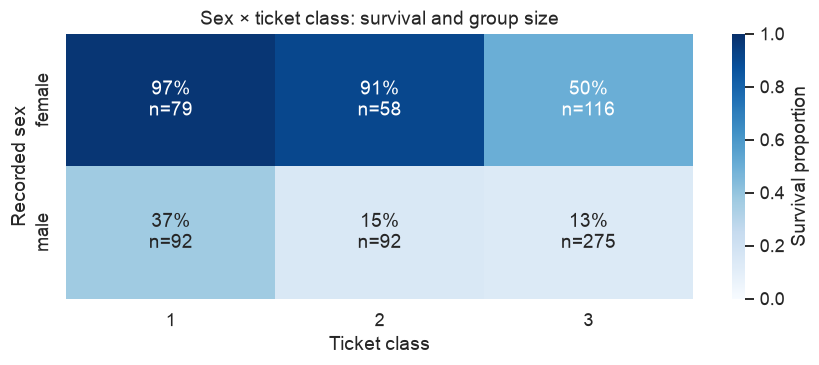

In [11]:
interaction = survival_summary(development, ["Sex", "Pclass"])
rates = interaction.rate.unstack("Pclass")
counts = interaction.passengers.unstack("Pclass")
labels = rates.map(lambda value: f"{value:.0%}").add("\nn=" + counts.fillna(0).astype(int).astype(str))
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(rates, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1,
            cbar_kws={"label": "Survival proportion"}, ax=ax)
ax.set(title="Sex × ticket class: survival and group size", xlabel="Ticket class", ylabel="Recorded sex")
plt.tight_layout()
plt.show()
show_table(interaction)

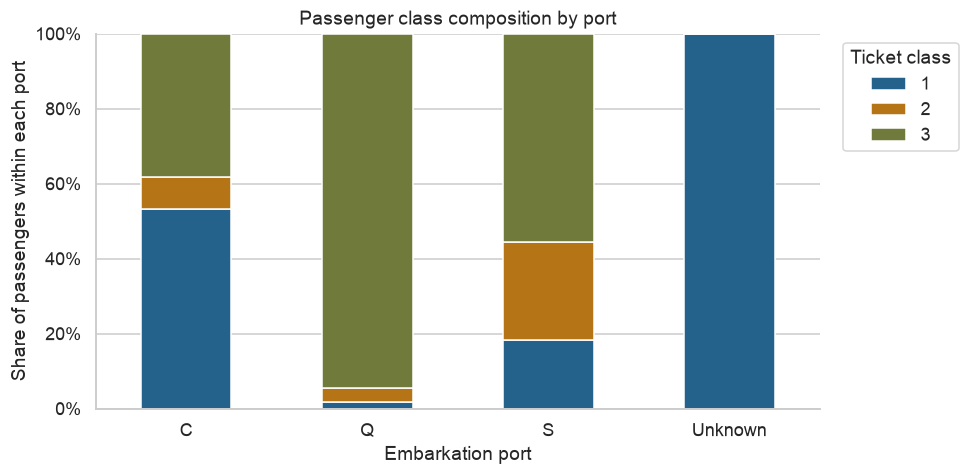

In [12]:
port_class_counts = pd.crosstab(development.Embarked.fillna("Unknown"), development.Pclass)
ax = port_class_counts.div(port_class_counts.sum(axis=1), axis=0).plot.bar(
    stacked=True, color=["#24628C", "#B57516", "#707A3B"], rot=0
)
ax.set(ylabel="Share of passengers within each port", xlabel="Embarkation port",
       title="Passenger class composition by port", ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(title="Ticket class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
show_table(survival_summary(development, ["Embarked", "Pclass"]))

Female survival ranges from **97.5% in class 1** to **50.0% in class 3**.
First-class passengers form a larger share of port C than port S.
Marginal differences do not isolate a port or class effect.

## 9. Numeric distributions and extreme values

,Age,Fare,SibSp,Parch
count,575.00,712.00,712.00,712.00
mean,29.81,31.82,0.49,0.39
std,14.49,48.06,1.06,0.84
min,0.42,0.00,0.00,0.00
1%,0.98,0.00,0.00,0.00
25%,21.00,7.90,0.00,0.00
50%,28.50,14.45,0.00,0.00
75%,39.00,31.00,1.00,0.00
95%,55.15,111.96,2.00,2.00
99%,67.04,227.52,4.89,4.00


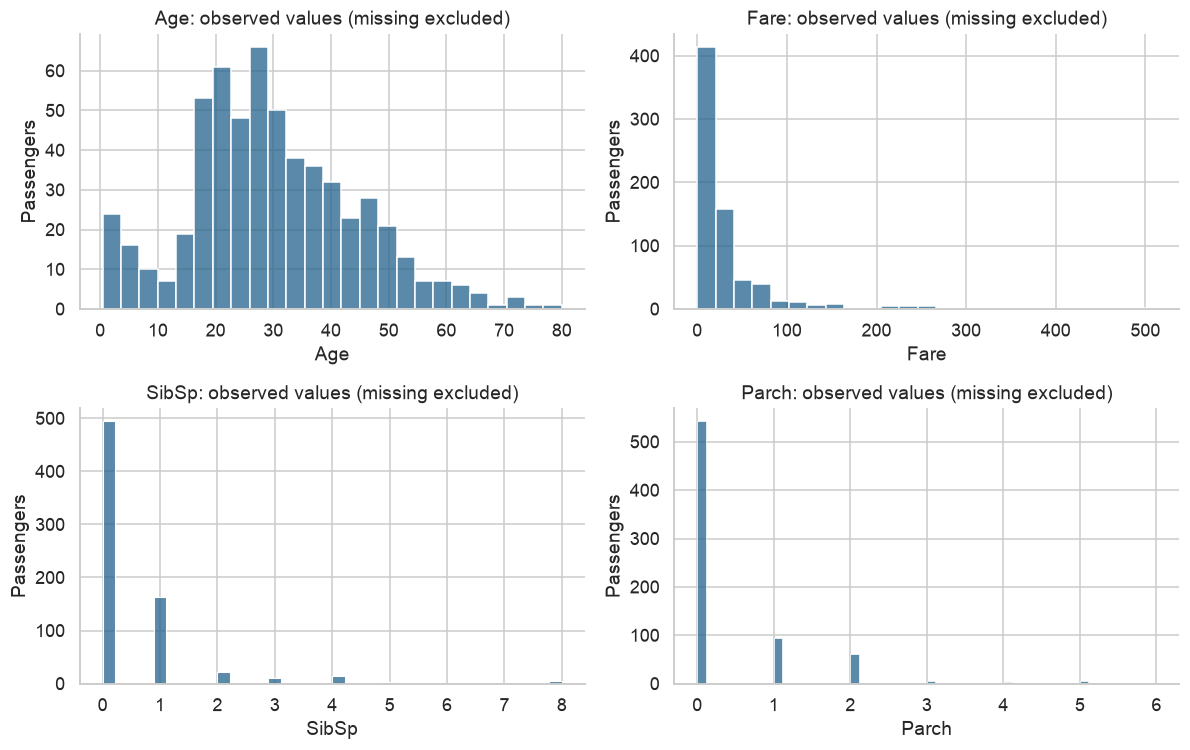

In [13]:
numeric = ["Age", "Fare", "SibSp", "Parch"]
display(development[numeric].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2))
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for column, ax in zip(numeric, axes.flat):
    sns.histplot(data=development, x=column, bins=25 if column in ["Age", "Fare"] else "auto",
                 color="#24628C", ax=ax)
    ax.set(title=f"{column}: observed values (missing excluded)", ylabel="Passengers")
plt.tight_layout()
plt.show()

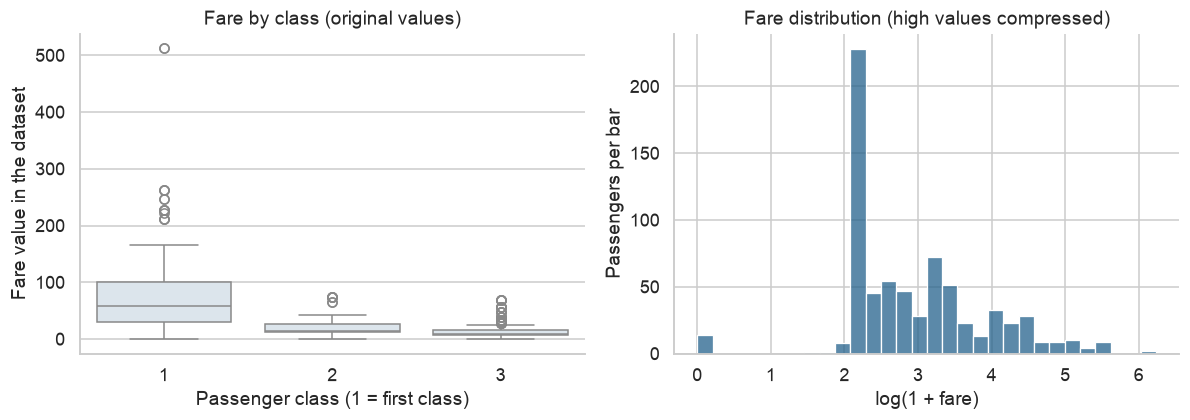

,PassengerId,Pclass,Fare,Ticket,SibSp,Parch
0,738,1,512.3292,PC 17755,0,0
1,259,1,512.3292,PC 17755,0,0
2,439,1,263.0000,19950,1,4
3,743,1,262.3750,PC 17608,2,2
4,312,1,262.3750,PC 17608,2,2
5,119,1,247.5208,PC 17558,0,1
6,300,1,247.5208,PC 17558,0,1
7,558,1,227.5250,PC 17757,0,0


,PassengerId,Pclass,Age,Fare
0,482,2,NaN,0.0
1,303,3,19.0,0.0
2,733,2,NaN,0.0
3,180,3,36.0,0.0
4,634,1,NaN,0.0
5,467,2,NaN,0.0
6,675,2,NaN,0.0
7,598,3,49.0,0.0
8,816,1,NaN,0.0
9,414,2,NaN,0.0


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=development, x="Pclass", y="Fare", color="#D9E6EF", ax=axes[0])
axes[0].set(title="Fare by class (original values)", xlabel="Passenger class (1 = first class)", ylabel="Fare value in the dataset")
sns.histplot(np.log1p(development.Fare.dropna()), bins=30, color="#24628C", ax=axes[1])
axes[1].set(title="Fare distribution (high values compressed)", xlabel="log(1 + fare)", ylabel="Passengers per bar")
plt.tight_layout()
plt.show()
display(development.nlargest(8, "Fare")[["PassengerId", "Pclass", "Fare", "Ticket", "SibSp", "Parch"]].reset_index(drop=True))
display(development.loc[development.Fare.eq(0), ["PassengerId", "Pclass", "Age", "Fare"]].head(10).reset_index(drop=True))

Fare skewness is **4.65**; `log1p(Fare)` skewness is **0.31**.
Two development passengers share the maximum recorded fare and ticket.
Skew reduction does not establish predictive improvement, and extreme values are not automatically errors.

## 10. Age and fare by survival outcome
Density histograms are normalized within each outcome. Missing values are excluded from these distributions.
Age bands are descriptive, with fixed boundaries rather than outcome-optimized cutoffs.

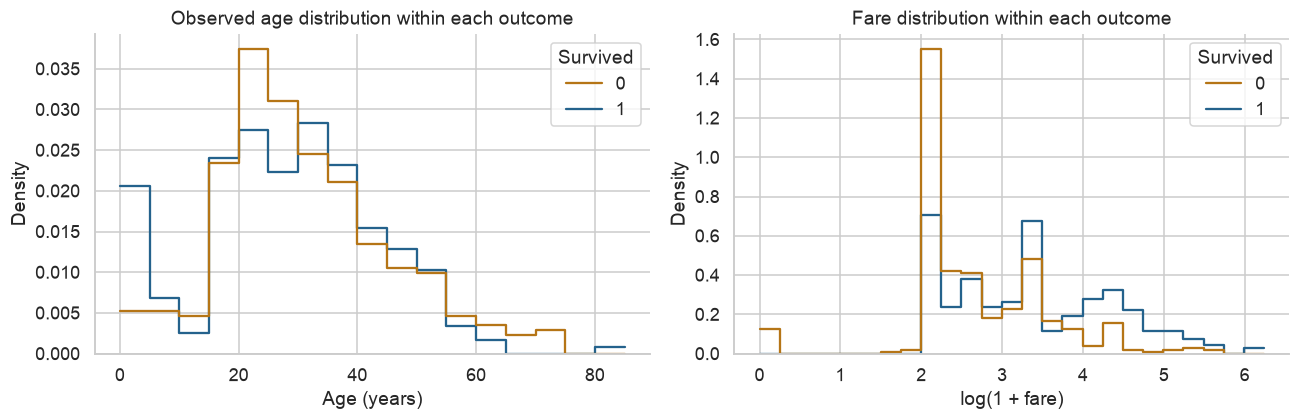

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=development, x="Age", hue="Survived", bins=np.arange(0, 86, 5),
             stat="density", common_norm=False, element="step", fill=False, palette=COLORS, ax=axes[0])
axes[0].set(title="Observed age distribution within each outcome", xlabel="Age (years)")
fare_view = development.assign(LogFare=np.log1p(development.Fare))
sns.histplot(data=fare_view, x="LogFare", hue="Survived", bins=25, stat="density",
             common_norm=False, element="step", fill=False, palette=COLORS, ax=axes[1])
axes[1].set(title="Fare distribution within each outcome", xlabel="log(1 + fare)")
plt.tight_layout()
plt.show()

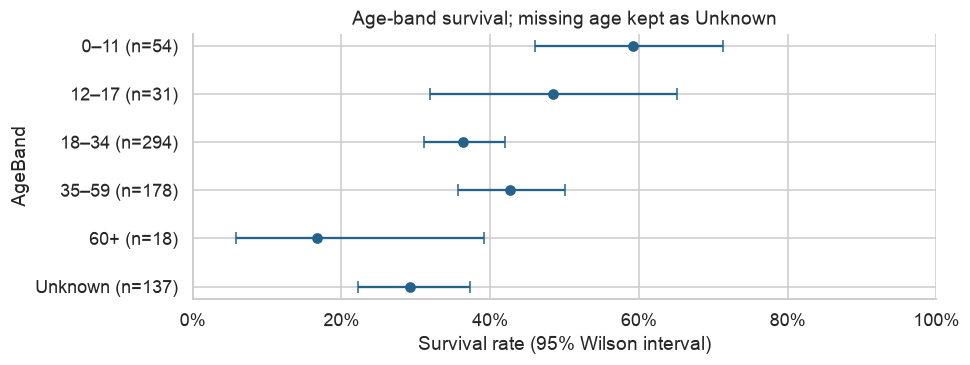

,passengers,survivors,rate,lower95,upper95
AgeBand,,,,,
0–11,54,32,59.3%,46.0%,71.3%
12–17,31,15,48.4%,32.0%,65.2%
18–34,294,107,36.4%,31.1%,42.0%
35–59,178,76,42.7%,35.7%,50.0%
60+,18,3,16.7%,5.8%,39.2%
Unknown,137,40,29.2%,22.2%,37.3%


In [16]:
age_view = development.assign(AgeBand=pd.cut(
    development.Age, [0, 12, 18, 35, 60, np.inf], right=False,
    labels=["0–11", "12–17", "18–34", "35–59", "60+"]
).astype("string").fillna("Unknown"))
age_rates = plot_survival(age_view, "AgeBand", "Age-band survival; missing age kept as Unknown")
show_table(age_rates)
show_table(survival_summary(age_view, ["Sex", "AgeBand"]))
age_context = development.assign(LifeStage=np.select(
    [development.Age.isna(), development.Age.lt(16)], ["Unknown", "Under 16"], default="16+"
))
show_table(survival_summary(age_context, ["Sex", "Pclass", "LifeStage"]))

## 11. Missingness by passenger group

AgeMissing          CabinMissing          
                    mean sum size         mean  sum size
Sex    Pclass                                           
female 1           0.101   8   79        0.152   12   79
       2           0.017   1   58        0.845   49   58
       3           0.259  30  116        0.957  111  116
male   1           0.196  18   92        0.250   23   92
       2           0.087   8   92        0.935   86   92
       3           0.262  72  275        0.985  271  275

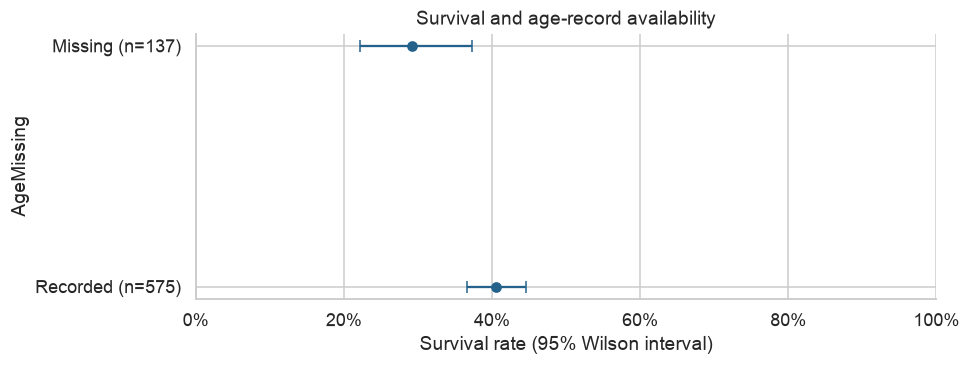

,passengers,survivors,rate,lower95,upper95
AgeMissing,,,,,
Missing,137,40,29.2%,22.2%,37.3%
Recorded,575,233,40.5%,36.6%,44.6%


In [17]:
missing_view = development.assign(
    AgeMissing=development.Age.isna().map({False: "Recorded", True: "Missing"}),
    CabinMissing=development.Cabin.isna().map({False: "Recorded", True: "Missing"}),
)
missing_by_group = development.assign(AgeMissing=development.Age.isna(), CabinMissing=development.Cabin.isna())
display(missing_by_group.groupby(["Sex", "Pclass"])[["AgeMissing", "CabinMissing"]].agg(["mean", "sum", "size"]).round(3))
show_table(plot_survival(missing_view, "AgeMissing", "Survival and age-record availability"))
show_table(survival_summary(missing_view, ["Pclass", "CabinMissing"]))

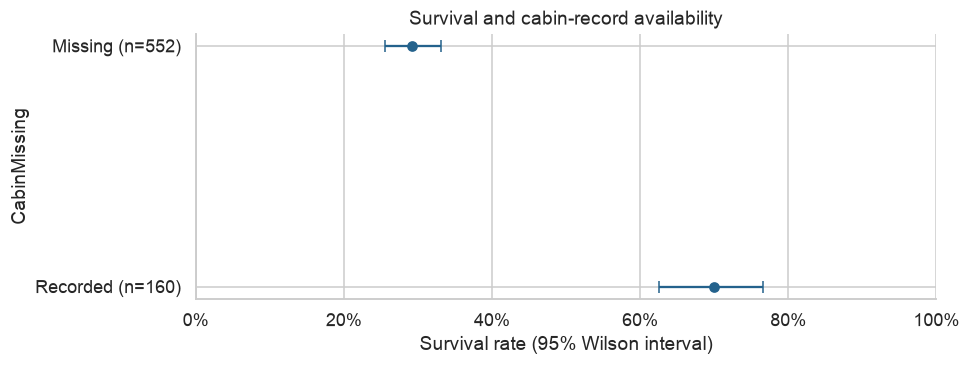

,passengers,survivors,rate,lower95,upper95
CabinMissing,,,,,
Missing,552,161,29.2%,25.5%,33.1%
Recorded,160,112,70.0%,62.5%,76.6%


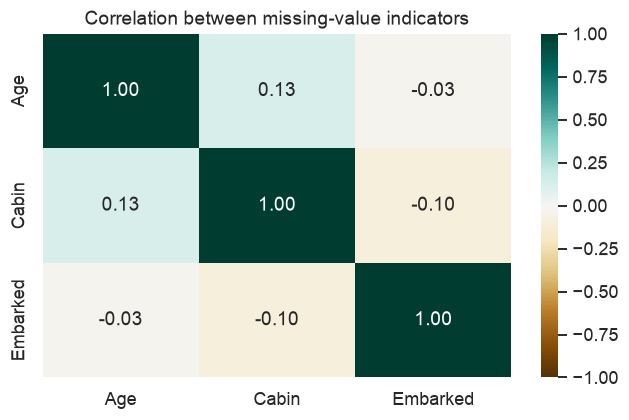

In [18]:
show_table(plot_survival(missing_view, "CabinMissing", "Survival and cabin-record availability"))
missing_columns = development.columns[development.isna().any()]
if len(missing_columns) > 1:
    co_missing = development[missing_columns].isna().astype(int).corr()
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(co_missing, annot=True, fmt=".2f", cmap="BrBG", vmin=-1, vmax=1, center=0, ax=ax)
    ax.set(title="Correlation between missing-value indicators")
    plt.tight_layout()
    plt.show()

Survival is **70.0%** with a recorded cabin versus **29.2%** without one.
Within class 1, rates are **69.9% (95/136)** versus **45.7% (16/35)**.
The recorded-cabin groups in classes 2 and 3 contain only 15 and 9 passengers.
Class composition does not account for the entire observed association; remaining differences may reflect other factors.

## 12. Age distributions within groups
Question: does one overall age replacement conceal meaningful differences between passenger groups?

observed  median  mean   std
Pclass Sex                                 
1      female        71    35.0  34.8  12.1
       male          74    40.0  41.1  15.3
2      female        57    29.0  29.7  13.3
       male          84    30.0  30.4  15.0
3      female        86    21.5  21.7  13.1
       male         203    26.0  27.1  12.5

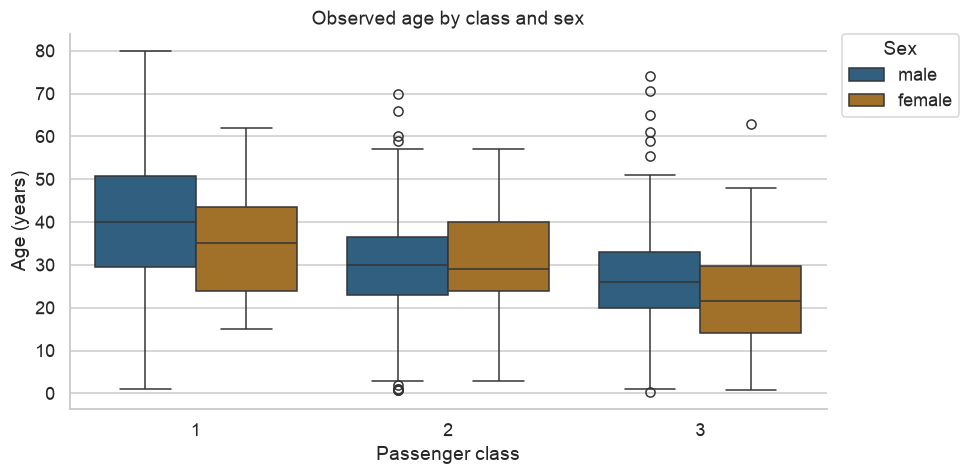

In [19]:
age_groups = development.groupby(["Pclass", "Sex"]).Age.agg(
    observed="count", median="median", mean="mean", std="std"
)
display(age_groups.round(1))
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=development, x="Pclass", y="Age", hue="Sex",
            palette={"female": "#B57516", "male": "#24628C"}, ax=ax)
ax.set(title="Observed age by class and sex", xlabel="Passenger class", ylabel="Age (years)")
ax.legend(title="Sex", loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.tight_layout()
plt.show()

Observed median age ranges from **21.5** for class-3 women to **40.0** for class-1 men.
Missing ages may follow a different distribution. Group-based imputation is tested within development folds.

## 13. Family size and composition

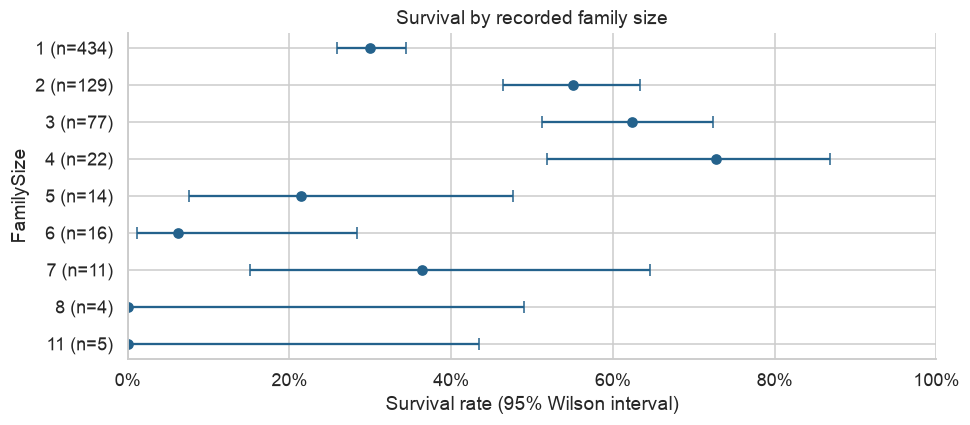

,passengers,survivors,rate,lower95,upper95
FamilySize,,,,,
1,434,130,30.0%,25.8%,34.4%
2,129,71,55.0%,46.4%,63.4%
3,77,48,62.3%,51.2%,72.3%
4,22,16,72.7%,51.8%,86.8%
5,14,3,21.4%,7.6%,47.6%
6,16,1,6.2%,1.1%,28.3%
7,11,4,36.4%,15.2%,64.6%
8,4,0,0.0%,0.0%,49.0%
11,5,0,0.0%,0.0%,43.4%


In [20]:
features = development.assign(FamilySize=development.SibSp + development.Parch + 1)
features["FamilyGroup"] = pd.cut(features.FamilySize, [0, 1, 4, np.inf], labels=["Alone", "2–4", "5+"])
family_rates = plot_survival(features, "FamilySize", "Survival by recorded family size")
show_table(family_rates)

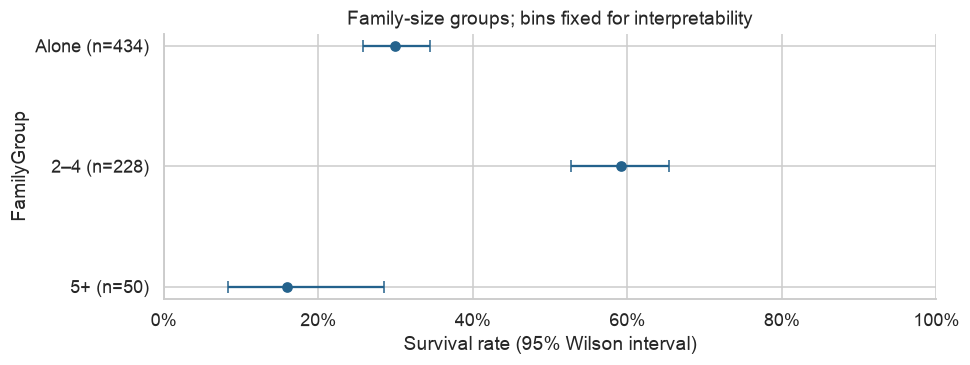

,passengers,survivors,rate,lower95,upper95
FamilyGroup,,,,,
Alone,434,130,30.0%,25.8%,34.4%
2–4,228,135,59.2%,52.7%,65.4%
5+,50,8,16.0%,8.3%,28.5%


In [21]:
family_group_rates = plot_survival(features, "FamilyGroup", "Family-size groups; bins fixed for interpretability")
show_table(family_group_rates)
family_sex = survival_summary(features, ["Sex", "FamilyGroup"])
show_table(family_sex)

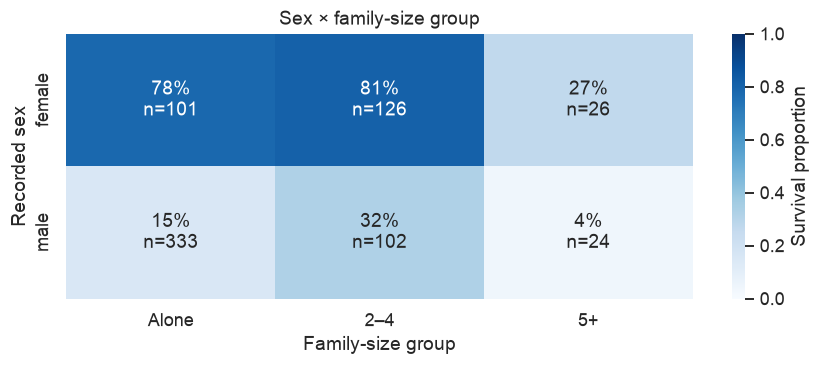

In [22]:
family_matrix = family_sex.rate.unstack("FamilyGroup")
family_counts = family_sex.passengers.unstack("FamilyGroup")
labels = family_matrix.map(lambda value: f"{value:.0%}").add(
    "\nn=" + family_counts.fillna(0).astype(int).astype(str)
)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(family_matrix, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1,
            cbar_kws={"label": "Survival proportion"}, ax=ax)
ax.set(title="Sex × family-size group", xlabel="Family-size group", ylabel="Recorded sex")
plt.tight_layout()
plt.show()

Survival is **30.0%** for solo passengers, **59.2%** for family sizes 2–4, and **16.0%** for sizes 5+.
The joint table checks whether this pattern persists within sex groups; aggregate rates also reflect population mix.
Family size is derived from existing columns and is not independent new information.

## 14. Titles and cabin information

,Passengers
Name,
Mr,412
Miss,141
Mrs,107
Master,31
Dr,6
Rev,5
Col,2
Mlle,2
Major,1


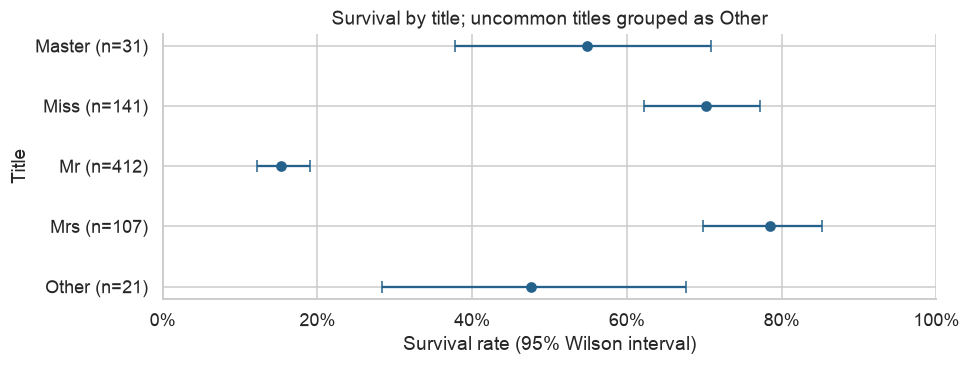

,passengers,survivors,rate,lower95,upper95
Title,,,,,
Master,31,17,54.8%,37.8%,70.8%
Miss,141,99,70.2%,62.2%,77.1%
Mr,412,63,15.3%,12.1%,19.1%
Mrs,107,84,78.5%,69.8%,85.2%
Other,21,10,47.6%,28.3%,67.6%


In [23]:
raw_title = features.Name.str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
features["Title"] = raw_title.where(raw_title.isin(["Mr", "Mrs", "Miss", "Master"]), "Other")
features["Deck"] = features.Cabin.str.extract(r"([A-Za-z])", expand=False).str.upper().fillna("Unknown")
display(raw_title.value_counts(dropna=False).rename("Passengers").to_frame())
title_rates = plot_survival(features, "Title", "Survival by title; uncommon titles grouped as Other")
show_table(title_rates)

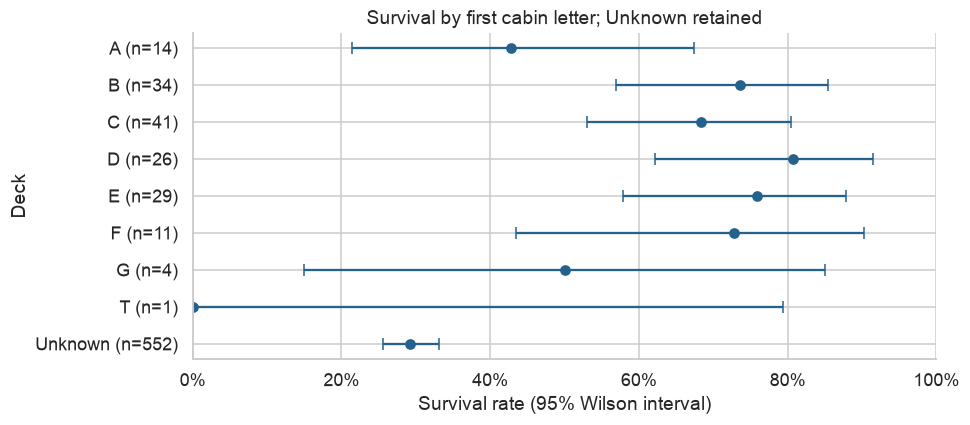

,passengers,survivors,rate,lower95,upper95
Deck,,,,,
A,14,6,42.9%,21.4%,67.4%
B,34,25,73.5%,56.9%,85.4%
C,41,28,68.3%,53.0%,80.4%
D,26,21,80.8%,62.1%,91.5%
E,29,22,75.9%,57.9%,87.8%
F,11,8,72.7%,43.4%,90.3%
G,4,2,50.0%,15.0%,85.0%
T,1,0,0.0%,0.0%,79.3%
Unknown,552,161,29.2%,25.5%,33.1%


,passengers,observed,median,missing_pct
Title,,,,
Master,31,28,3.0,9.7
Miss,141,115,21.0,18.4
Mr,412,318,30.0,22.8
Mrs,107,94,35.0,12.1
Other,21,20,48.5,4.8


In [24]:
deck_rates = plot_survival(features, "Deck", "Survival by first cabin letter; Unknown retained")
show_table(deck_rates)
title_age = features.groupby("Title", observed=True).Age.agg(passengers="size", observed="count", median="median")
title_age["missing_pct"] = (1 - title_age.observed / title_age.passengers).mul(100)
display(title_age.round(1))

Master has a median observed age of **3 years** (28 recorded ages among 31 passengers).
Age missingness is **22.8%** for Mr and **9.7%** for Master.
Several original titles and deck categories have very small samples.

## 15. Numeric correlations
Pearson correlations use pairwise observed values. Pairwise sample counts are reported below.

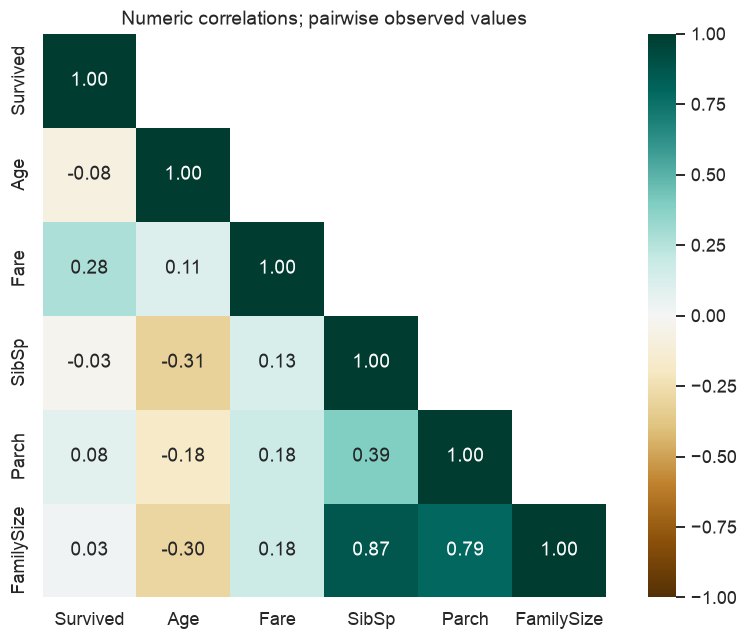

,Survived,Age,Fare,SibSp,Parch,FamilySize
Pairwise sample counts,,,,,,
Survived,712,575,712,712,712,712
Age,575,575,575,575,575,575
Fare,712,575,712,712,712,712
SibSp,712,575,712,712,712,712
Parch,712,575,712,712,712,712
FamilySize,712,575,712,712,712,712


In [25]:
correlation_columns = ["Survived", "Age", "Fare", "SibSp", "Parch", "FamilySize"]
correlation = features[correlation_columns].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation, mask=np.triu(np.ones_like(correlation, dtype=bool), k=1),
            annot=True, fmt=".2f", cmap="BrBG", vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.grid(False)
ax.set(title="Numeric correlations; pairwise observed values")
plt.tight_layout()
plt.show()
observed = features[correlation_columns].notna().astype(int)
display(observed.T.dot(observed).rename_axis("Pairwise sample counts"))

## 16. Travel groups and split dependence
Ticket keys normalize case and whitespace. Family keys combine surname and recorded family size;
solo passengers receive unique keys. Family keys are approximate and can miss or merge relationships.

In [26]:
def group_keys(frame):
    size = frame.SibSp + frame.Parch + 1
    surname = frame.Name.str.split(",", n=1).str[0].str.strip().str.lower()
    family = surname + "_" + size.astype(str)
    family = family.where(size.gt(1), "solo_" + frame.PassengerId.astype(str))
    ticket = frame.Ticket.astype("string").str.upper().str.replace(r"\s+", "", regex=True)
    ticket = ticket.fillna("unknown_" + frame.PassengerId.astype(str))
    return pd.DataFrame({"Ticket": ticket, "ApproxFamily": family}, index=frame.index)


dev_keys, val_keys = group_keys(development), group_keys(holdout_features)
overlap_rows = []
for key in dev_keys:
    shared = set(dev_keys[key]) & set(val_keys[key])
    overlap_rows.append({"Group key": key, "Shared groups": len(shared),
                         "Development passengers in shared groups": int(dev_keys[key].isin(shared).sum()),
                         "Validation passengers in shared groups": int(val_keys[key].isin(shared).sum())})
overlap = pd.DataFrame(overlap_rows)
display(overlap.style.hide(axis="index"))
ticket_sizes = dev_keys.Ticket.value_counts()
counts = ticket_sizes.value_counts().sort_index()
display(
    counts.rename_axis("Passengers per ticket")
          .reset_index(name="Number of tickets")
          .style.hide(axis="index")
)

Group key,Shared groups,Development passengers in shared groups,Validation passengers in shared groups
Ticket,61,111,67
ApproxFamily,41,79,46


Passengers per ticket,Number of tickets
1,476
2,69
3,14
4,6
5,4
6,2


In [27]:
ticket_summary = development.assign(TicketGroup=dev_keys.Ticket).groupby("TicketGroup").Survived.agg(
    passengers="size", outcome_types="nunique"
)
shared_tickets = ticket_summary.loc[ticket_summary.passengers.gt(1)]
display(pd.Series({
    "Development multi-passenger tickets": len(shared_tickets),
    "Multi-passenger tickets with one observed outcome": int(shared_tickets.outcome_types.eq(1).sum()),
    "Multi-passenger tickets with mixed outcomes": int(shared_tickets.outcome_types.gt(1).sum()),
}, name="Count").to_frame())

,Count
Development multi-passenger tickets,95
Multi-passenger tickets with one observed outcome,69
Multi-passenger tickets with mixed outcomes,26


In [28]:
ticket_audit = development.assign(TicketKey=dev_keys.Ticket).groupby("TicketKey").agg(
    observed_passengers=("PassengerId", "size"),
    distinct_fares=("Fare", "nunique"),
    distinct_surnames=("Name", lambda names: names.str.split(",", n=1).str[0].nunique()),
)
shared_ticket_audit = ticket_audit.loc[ticket_audit.observed_passengers.gt(1)]
display(pd.Series({
    "Multi-passenger tickets in development": len(shared_ticket_audit),
    "Tickets with one recorded fare value": shared_ticket_audit.distinct_fares.eq(1).sum(),
    "Tickets with multiple surnames": shared_ticket_audit.distinct_surnames.gt(1).sum(),
}).to_frame("Ticket groups"))

,Ticket groups
Multi-passenger tickets in development,95
Tickets with one recorded fare value,95
Tickets with multiple surnames,30


**67/179 validation passengers** share tickets with development passengers; **46/179** share an approximate family key.
All **95** development multi-passenger tickets have one recorded fare value; **30** span multiple surnames.
This supports investigating ticket-level fare semantics.

## 17. Questions from EDA
The following questions guided the development experiments. Results are in [RESULTS.md](RESULTS.md).

| Observation | Hypothesis | Evidence needed |
| --- | --- | --- |
| Age differs across groups and is incomplete | Group context may help age imputation | Compare overall and grouped imputation within folds |
| Cabin availability tracks survival within classes | Availability may add information beyond class | Compare with and without an availability indicator |
| Family survival is nonmonotonic | A family-size representation may help | Compare raw counts and derived family features |
| Title overlaps with age and sex | Title may help for children or missing ages | Feature ablation on identical development folds |
| Fare is skewed and repeated within tickets | Log fare or a ticket-aware representation may help | Check payment semantics and compare fold-local variants |
| Travel groups cross the split | Scores may depend on shared groups | Compare passenger and grouped development splits |

## 18. Consistency checks

In [29]:
assert target_counts.sum() == len(development)
assert target_counts.loc[1] == development.Survived.sum()
assert set(development.PassengerId).isdisjoint(holdout_features.PassengerId)
assert features.FamilySize.ge(1).all()
for table in [sex_rates, class_rates, port_rates, age_rates, family_rates, title_rates, deck_rates]:
    assert table.passengers.sum() == len(development)
    assert table.survivors.sum() == development.Survived.sum()
    assert table.lower95.le(table.rate + 1e-12).all()
    assert table.upper95.ge(table.rate - 1e-12).all()
    assert table[["rate", "lower95", "upper95"]].ge(0).all().all()
    assert table[["rate", "lower95", "upper95"]].le(1).all().all()
print("All EDA consistency checks passed.")

All EDA consistency checks passed.


In [30]:
findings = {
    "development_passengers": len(development),
    "reserved_validation_passengers": len(holdout_features),
    "development_survival_rate": float(development.Survived.mean()),
    "majority_development_accuracy": float(majority_accuracy),
    "missing_counts": development.isna().sum().astype(int).to_dict(),
    "survival_by_sex": sex_rates.reset_index().to_dict(orient="records"),
    "survival_by_class": class_rates.reset_index().to_dict(orient="records"),
    "split_group_overlap": overlap.to_dict(orient="records"),
    "zero_fares": int(development.Fare.eq(0).sum()),
    "fare_skew": float(development.Fare.skew()),
    "holdout_labels_used_for_eda": False,
    "models_trained": False,
    "sex_class_rates": interaction.reset_index().to_dict(orient="records"),
    "family_group_rates": family_group_rates.reset_index().to_dict(orient="records"),
    "log_fare_skew": float(np.log1p(development.Fare).skew()),
}
(OUTPUT / "findings.json").write_text(json.dumps(findings, indent=2) + "\n")

3838